# Customer Conversion Analysis

## Project Objective

To analyze whether marketing spend is associated with customer conversions, identify which campaigns and customer segments perform better, and evaluate opportunities to improve marketing effectiveness and cost efficiency.

## 1. Data Quality Checks

In [273]:
import pandas as pd 
import numpy as np 


In [274]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [275]:
import scipy.stats as stats

In [276]:
import matplotlib.pyplot as plt

In [277]:
import seaborn as sns

In [278]:
df = pd.read_csv(r"C:\Users\acer\Desktop\Digital Marketing Analysis\Digital Marketing Analysis\Digital_Marketing_dataset\digital_marketing_campaign_dataset.csv")

In [279]:
df.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [280]:
df.shape

(8000, 20)

In [281]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   str    
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   str    
 5   CampaignType         8000 non-null   str    
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchases    8000 non-null   int64  
 16 

In [282]:
df["CustomerID"].duplicated().sum()

np.int64(0)

In [283]:
df.isnull().sum()

CustomerID             0
Age                    0
Gender                 0
Income                 0
CampaignChannel        0
CampaignType           0
AdSpend                0
ClickThroughRate       0
ConversionRate         0
WebsiteVisits          0
PagesPerVisit          0
TimeOnSite             0
SocialShares           0
EmailOpens             0
EmailClicks            0
PreviousPurchases      0
LoyaltyPoints          0
AdvertisingPlatform    0
AdvertisingTool        0
Conversion             0
dtype: int64

In [284]:
df["CampaignChannel"].unique()

<StringArray>
['Social Media', 'Email', 'PPC', 'Referral', 'SEO']
Length: 5, dtype: str

In [285]:
df["Gender"].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [286]:
df["CampaignType"].unique()

<StringArray>
['Awareness', 'Retention', 'Conversion', 'Consideration']
Length: 4, dtype: str

In [287]:
df["AdvertisingPlatform"].unique()

<StringArray>
['IsConfid']
Length: 1, dtype: str

In [288]:
df["AdvertisingTool"].unique()

<StringArray>
['ToolConfid']
Length: 1, dtype: str

In [289]:
df["Conversion"].unique()

array([1, 0])

## 2. Customer Demographics

In [290]:
df.describe()

,CustomerID,Age,Income,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,Conversion
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,11999.50000,43.625500,84664.196750,5000.944830,0.154829,0.104389,24.751625,5.549299,7.727718,49.799750,9.476875,4.467375,4.485500,2490.268500,0.876500
std,2309.54541,14.902785,37580.387945,2838.038153,0.084007,0.054878,14.312269,2.607358,4.228218,28.901165,5.711111,2.856564,2.888093,1429.527162,0.329031
min,8000.00000,18.000000,20014.000000,100.054813,0.010005,0.010018,0.000000,1.000428,0.501669,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9999.75000,31.000000,51744.500000,2523.221165,0.082635,0.056410,13.000000,3.302479,4.068340,25.000000,5.000000,2.000000,2.000000,1254.750000,1.000000
50%,11999.50000,43.000000,84926.500000,5013.440044,0.154505,0.104046,25.000000,5.534257,7.682956,50.000000,9.000000,4.000000,4.000000,2497.000000,1.000000
75%,13999.25000,56.000000,116815.750000,7407.989369,0.228207,0.152077,37.000000,7.835756,11.481468,75.000000,14.000000,7.000000,7.000000,3702.250000,1.000000
max,15999.00000,69.000000,149986.000000,9997.914781,0.299968,0.199995,49.000000,9.999055,14.995311,99.000000,19.000000,9.000000,9.000000,4999.000000,1.000000


In [291]:
Q1 = df["AdSpend"].quantile(0.25)
Q3 = df["AdSpend"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1-1.5*(IQR)
upper_bound = Q3+1.5*(IQR)
outliers = df["AdSpend"][
    (df["AdSpend"] < lower_bound) |
    (df["AdSpend"] > upper_bound)]
outliers.count()

np.int64(0)

In [292]:
Q1 = df["Income"].quantile(0.25)
Q3 = df["Income"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1-1.5*(IQR)
upper_bound = Q3+1.5*(IQR)
outliers = df["Income"][
    (df["Income"] < lower_bound) |
    (df["Income"] > upper_bound)]
outliers.count()

np.int64(0)

In [293]:
Q1 = df["WebsiteVisits"].quantile(0.25)
Q3 = df["WebsiteVisits"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1-1.5*(IQR)
upper_bound = Q3+1.5*(IQR)
outliers = df["WebsiteVisits"][
    (df["WebsiteVisits"] < lower_bound) |
    (df["WebsiteVisits"] > upper_bound)]
outliers.count()

np.int64(0)

In [294]:
df["Conversion"].value_counts()

Conversion
1    7012
0     988
Name: count, dtype: int64

In [295]:
df["Age"].value_counts().sort_index()

Age
18    148
19    150
20    151
21    160
22    139
23    154
24    129
25    162
26    143
27    136
28    153
29    148
30    157
31    148
32    157
33    148
34    177
35    155
36    153
37    156
38    162
39    165
40    170
41    151
42    167
43    178
44    128
45    173
46    165
47    150
48    120
49    173
50    149
51    155
52    172
53    149
54    160
55    143
56    147
57    157
58    144
59    146
60    139
61    150
62    182
63    140
64    187
65    137
66    178
67    137
68    155
69    147
Name: count, dtype: int64

In [296]:
df["Age_Group"] = pd.cut(df["Age"], bins=[18, 30, 40, 50, 60, 70],
    right=False,
    labels=["18-29", "30-39", "40-49", "50-59", "60-69"])
df["Age_Group"].value_counts()

Age_Group
18-29    1773
30-39    1578
40-49    1575
60-69    1552
50-59    1522
Name: count, dtype: int64

In [297]:
Age_Conversion = df.groupby("Age_Group")["Conversion"].mean() * 100
Age_Conversion

Age_Group
18-29    87.535251
30-39    87.325729
40-49    88.761905
50-59    86.925099
60-69    87.693299
Name: Conversion, dtype: float64

In [298]:
df["Gender"].value_counts()

Gender
Female    4839
Male      3161
Name: count, dtype: int64

In [299]:
Gender_Conversion = df.groupby("Gender")["Conversion"].mean() * 100
Gender_Conversion

Gender
Female    87.621409
Male      87.693768
Name: Conversion, dtype: float64

In [300]:
df["Income"].describe()

count      8000.000000
mean      84664.196750
std       37580.387945
min       20014.000000
25%       51744.500000
50%       84926.500000
75%      116815.750000
max      149986.000000
Name: Income, dtype: float64

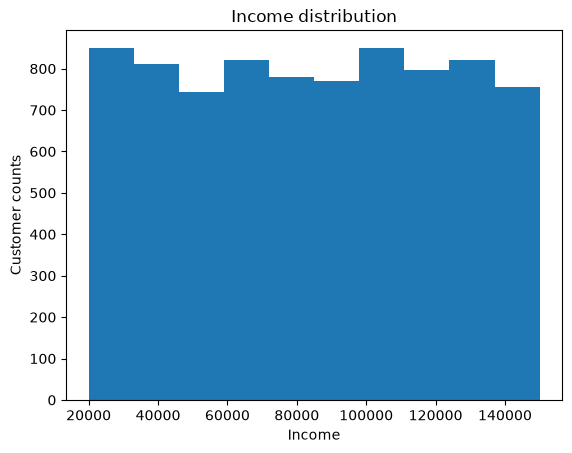

In [301]:
plt.hist(df["Income"], bins=10)
plt.xlabel("Income")
plt.ylabel("Customer counts")
plt.title("Income distribution")
plt.show()

In [302]:
df["Income_Category"] = pd.qcut(
    df["Income"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"])
df["Income_Category"].value_counts()

Income_Category
Q1    2000
Q2    2000
Q3    2000
Q4    2000
Name: count, dtype: int64

In [303]:
df.groupby("Income_Category")["Conversion"].value_counts()

Income_Category  Conversion
Q1               1             1730
                 0              270
Q2               1             1764
                 0              236
Q3               1             1756
                 0              244
Q4               1             1762
                 0              238
Name: count, dtype: int64

In [304]:
Income_Conversion = df.groupby("Income_Category", observed=True)["Conversion"].mean() * 100

In [305]:
df["LoyaltyPoints"].describe()

count    8000.000000
mean     2490.268500
std      1429.527162
min         0.000000
25%      1254.750000
50%      2497.000000
75%      3702.250000
max      4999.000000
Name: LoyaltyPoints, dtype: float64

## 3. Understanding the Target Variable

In [306]:
Conversion_Rate = 100 * (df["Conversion"].value_counts()[1]) / len(df)
Conversion_Rate

np.float64(87.65)

Approximately 87.65% of the customer records in the dataset are marked as converted. Further analysis is required to assess marketing effectiveness.

In [307]:
Campaign_Channel_Conversion = df.groupby("CampaignChannel")["Conversion"].sum()
Campaign_Channel_Conversion

CampaignChannel
Email           1355
PPC             1461
Referral        1518
SEO             1359
Social Media    1319
Name: Conversion, dtype: int64

In [308]:
Campaign_Channel = df.groupby("CampaignChannel").size()
Campaign_Channel

CampaignChannel
Email           1557
PPC             1655
Referral        1719
SEO             1550
Social Media    1519
dtype: int64

In [309]:
Campaign_Channel_Conversion_Rate = (Campaign_Channel_Conversion * 100 )/Campaign_Channel
Campaign_Channel_Conversion_Rate

CampaignChannel
Email           87.026333
PPC             88.277946
Referral        88.307155
SEO             87.677419
Social Media    86.833443
dtype: float64

In [310]:
AdSpend_by_CampaignChannel = df.groupby("CampaignChannel")["AdSpend"].sum()
AdSpend_by_CampaignChannel

CampaignChannel
Email           7.871576e+06
PPC             8.199237e+06
Referral        8.653519e+06
SEO             7.740904e+06
Social Media    7.542323e+06
Name: AdSpend, dtype: float64

In [311]:
AVG_AdSpend_by_CampaignChannel = df.groupby("CampaignChannel")["AdSpend"].mean()
AVG_AdSpend_by_CampaignChannel

CampaignChannel
Email           5055.604272
PPC             4954.221741
Referral        5034.042284
SEO             4994.131533
Social Media    4965.321428
Name: AdSpend, dtype: float64

In [312]:
cost_per_converted_customer = AdSpend_by_CampaignChannel /Campaign_Channel_Conversion
cost_per_converted_customer

CampaignChannel
Email           5809.281071
PPC             5612.071856
Referral        5700.605195
SEO             5696.029342
Social Media    5718.213229
dtype: float64

In [313]:
df["ConversionRate"].describe()

count    8000.000000
mean        0.104389
std         0.054878
min         0.010018
25%         0.056410
50%         0.104046
75%         0.152077
max         0.199995
Name: ConversionRate, dtype: float64

In [314]:
Campaign_Type_Conversion = df.groupby("CampaignType")["Conversion"].sum()
Campaign_Type_Conversion

CampaignType
Awareness        1701
Consideration    1701
Conversion       1939
Retention        1671
Name: Conversion, dtype: int64

In [315]:
Campaign_Type = df.groupby("CampaignType").size()
Campaign_Type

CampaignType
Awareness        1988
Consideration    1988
Conversion       2077
Retention        1947
dtype: int64

In [316]:
Campaign_Type_Conversion_Rate = Campaign_Type_Conversion*100/Campaign_Type
Campaign_Type_Conversion_Rate

CampaignType
Awareness        85.563380
Consideration    85.563380
Conversion       93.355802
Retention        85.824345
dtype: float64

In [317]:
Campaign_Type_Channel = df.groupby(["CampaignType", "CampaignChannel"])["Conversion"].sum().unstack()
Campaign_Type_Channel

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,318,354,381,331,317
Consideration,345,351,348,313,344
Conversion,388,420,414,378,339
Retention,304,336,375,337,319


In [318]:
Campaign_Type_Channel_total = df.groupby(["CampaignType", "CampaignChannel"]).size()
Campaign_Type_Channel_total


CampaignType   CampaignChannel
Awareness      Email              378
               PPC                412
               Referral           431
               SEO                390
               Social Media       377
Consideration  Email              403
               PPC                404
               Referral           407
               SEO                369
               Social Media       405
Conversion     Email              416
               PPC                447
               Referral           445
               SEO                402
               Social Media       367
Retention      Email              360
               PPC                392
               Referral           436
               SEO                389
               Social Media       370
dtype: int64

In [319]:
Campaign_Type_Channel_Rate = (
    df.groupby(["CampaignType", "CampaignChannel"])["Conversion"]
    .mean()
    .mul(100)
    .unstack())

Campaign_Type_Channel_Rate

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,84.126984,85.922330,88.399072,84.871795,84.084881
Consideration,85.607940,86.881188,85.503686,84.823848,84.938272
Conversion,93.269231,93.959732,93.033708,94.029851,92.370572
Retention,84.444444,85.714286,86.009174,86.632391,86.216216


In [320]:
Campaign_Type_Spent = df.groupby("CampaignType")["AdSpend"].sum()
Campaign_Type_Spent

CampaignType
Awareness        1.007785e+07
Consideration    9.861274e+06
Conversion       1.030008e+07
Retention        9.768362e+06
Name: AdSpend, dtype: float64

In [321]:
Campaign_Type_Channel_Spent = df.groupby(["CampaignType","CampaignChannel"])["AdSpend"].sum().unstack()
Campaign_Type_Channel_Spent



CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,1.845084e+06,2.056792e+06,2.220263e+06,2.001481e+06,1.954227e+06
Consideration,2.002153e+06,2.021319e+06,2.036699e+06,1.824554e+06,1.976548e+06
Conversion,2.150688e+06,2.157813e+06,2.226189e+06,1.980840e+06,1.784546e+06
Retention,1.873651e+06,1.963313e+06,2.170368e+06,1.934028e+06,1.827002e+06


In [322]:
Campaign_Type_Channel_Cost_Per_Conversion = Campaign_Type_Channel_Spent / Campaign_Type_Channel
Campaign_Type_Channel_Cost_Per_Conversion

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,5802.150667,5810.146538,5827.461147,6046.769112,6164.753208
Consideration,5803.341314,5758.744016,5852.584055,5829.247546,5745.779182
Conversion,5543.011284,5137.650019,5377.267924,5240.318690,5264.148111
Retention,6163.325027,5843.193301,5787.647512,5738.956536,5727.279731


In [323]:
Campaign_Type_CTR = df.groupby("CampaignType")["ClickThroughRate"].mean()
Campaign_Type_CTR

CampaignType
Awareness        0.155764
Consideration    0.151798
Conversion       0.155665
Retention        0.156076
Name: ClickThroughRate, dtype: float64

In [324]:
Campaign_Channel_CTR = df.groupby("CampaignChannel")["ClickThroughRate"].mean()
Campaign_Channel_CTR

CampaignChannel
Email           0.155609
PPC             0.158307
Referral        0.151673
SEO             0.153150
Social Media    0.155523
Name: ClickThroughRate, dtype: float64

In [325]:
Campaign_Type_Channel_CTR = df.groupby(["CampaignType","CampaignChannel"])["ClickThroughRate"].mean().unstack()
Campaign_Type_Channel_CTR

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,0.151545,0.164482,0.156160,0.154256,0.151575
Consideration,0.153286,0.156585,0.146247,0.153421,0.149641
Conversion,0.157508,0.153070,0.154299,0.153096,0.161207
Retention,0.160282,0.159564,0.149621,0.151842,0.160345


In [326]:
Campaign_Channel_WV = df.groupby("CampaignChannel")["WebsiteVisits"].mean()
Campaign_Channel_WV

CampaignChannel
Email           24.878613
PPC             24.155287
Referral        24.890634
SEO             24.740000
Social Media    25.125741
Name: WebsiteVisits, dtype: float64

In [327]:
Campaign_Type_WV = df.groupby("CampaignType")["WebsiteVisits"].mean()
Campaign_Type_WV

CampaignType
Awareness        24.759557
Consideration    25.302314
Conversion       24.376023
Retention        24.581921
Name: WebsiteVisits, dtype: float64

In [328]:
Campaign_Type_Channel_WV = df.groupby(["CampaignType","CampaignChannel"])["WebsiteVisits"].mean().unstack()
Campaign_Type_Channel_WV

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,24.621693,25.618932,24.113689,23.533333,25.965517
Consideration,26.047146,24.128713,24.518428,26.983740,24.987654
Conversion,24.158654,23.252796,25.510112,24.320896,24.675749
Retention,24.672222,23.673469,25.373853,24.254499,24.867568


In [329]:
df["PagesPerVisit"].describe()

count    8000.000000
mean        5.549299
std         2.607358
min         1.000428
25%         3.302479
50%         5.534257
75%         7.835756
max         9.999055
Name: PagesPerVisit, dtype: float64

In [330]:
conversionPagePerVisit = df.groupby("Conversion")["PagesPerVisit"].mean()
conversionPagePerVisit

Conversion
0    4.835002
1    5.649945
Name: PagesPerVisit, dtype: float64

In [331]:
Campaign_Type_Channel_PagePerVisit = df.groupby(["CampaignType","CampaignChannel"])["PagesPerVisit"].mean().unstack()
Campaign_Type_Channel_PagePerVisit

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,5.724649,5.559037,5.512115,5.746330,5.600530
Consideration,5.544656,5.544815,5.754709,5.462731,5.625947
Conversion,5.435843,5.658691,5.534038,5.267758,5.619527
Retention,5.541225,5.438810,5.382883,5.554965,5.494239


In [332]:
conversionTimeOnSite = df.groupby("Conversion")["TimeOnSite"].mean()
conversionTimeOnSite

Conversion
0    6.267871
1    7.933413
Name: TimeOnSite, dtype: float64

In [333]:
Campaign_Type_Channel_TimeOnSite = df.groupby(["CampaignType","CampaignChannel"])["TimeOnSite"].mean().unstack()
Campaign_Type_Channel_TimeOnSite

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,7.572267,8.003788,7.718229,7.541611,7.969959
Consideration,7.662909,7.599237,7.741440,7.672777,7.517648
Conversion,7.839523,7.896046,7.647307,7.809833,7.912199
Retention,7.627839,7.857392,7.504566,7.441747,8.038890


In [334]:
conversionSocialShares = df.groupby("Conversion")["SocialShares"].mean()
conversionSocialShares

Conversion
0    50.681174
1    49.675556
Name: SocialShares, dtype: float64

In [335]:
Campaign_Type_Channel_SocialShares = df.groupby(["CampaignType","CampaignChannel"])["SocialShares"].mean().unstack()
Campaign_Type_Channel_SocialShares

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,49.621693,50.395631,50.556845,50.200000,51.748011
Consideration,47.612903,49.670792,51.203931,49.146341,50.106173
Conversion,50.055288,48.407159,50.550562,48.328358,51.411444
Retention,50.927778,50.081633,47.782110,48.478149,50.186486


In [336]:
conversionEmailOpens = df.groupby("Conversion")["EmailOpens"].mean()
conversionEmailOpens

Conversion
0    7.576923
1    9.744581
Name: EmailOpens, dtype: float64

In [337]:
Campaign_Type_Channel_EmailOpens = df.groupby(["CampaignType","CampaignChannel"])["EmailOpens"].mean().unstack()
Campaign_Type_Channel_EmailOpens

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,9.981481,9.458738,9.482599,9.189744,9.339523
Consideration,9.406948,9.324257,9.565111,9.192412,9.214815
Conversion,9.120192,8.856823,9.707865,9.554726,10.335150
Retention,9.472222,9.625000,9.612385,9.740360,9.481081


In [338]:
conversionEmailClicks = df.groupby("Conversion")["EmailClicks"].mean()
conversionEmailClicks

Conversion
0    3.481781
1    4.606246
Name: EmailClicks, dtype: float64

In [339]:
Campaign_Type_Channel_EmailClicks = df.groupby(["CampaignType","CampaignChannel"])["EmailClicks"].mean().unstack()
Campaign_Type_Channel_EmailClicks

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,4.455026,4.434466,4.515081,4.192308,4.405836
Consideration,4.593052,4.502475,4.707617,4.246612,4.409877
Conversion,4.612981,4.516779,4.503371,4.363184,4.749319
Retention,4.369444,4.385204,4.396789,4.483290,4.472973


In [340]:
conversionPreviousPurchases = df.groupby("Conversion")["PreviousPurchases"].mean()
conversionPreviousPurchases

Conversion
0    3.625506
1    4.606674
Name: PreviousPurchases, dtype: float64

In [341]:
Campaign_Type_Channel_PreviousPurchases = df.groupby(["CampaignType","CampaignChannel"])["PreviousPurchases"].mean().unstack()
Campaign_Type_Channel_PreviousPurchases

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,4.523810,4.351942,4.320186,4.192308,4.477454
Consideration,4.756824,4.539604,4.422604,4.612466,4.224691
Conversion,4.519231,4.440716,4.582022,4.788557,4.558583
Retention,4.422222,4.346939,4.605505,4.480720,4.548649


In [342]:
conversionLoyaltyPoints = df.groupby("Conversion")["LoyaltyPoints"].mean()
conversionLoyaltyPoints

Conversion
0    2128.483806
1    2541.244438
Name: LoyaltyPoints, dtype: float64

In [343]:
Campaign_Type_Channel_LoyaltyPoints = df.groupby(["CampaignType","CampaignChannel"])["LoyaltyPoints"].mean().unstack()
Campaign_Type_Channel_LoyaltyPoints

CampaignChannel,Email,PPC,Referral,SEO,Social Media
CampaignType,,,,,
Awareness,2560.275132,2385.915049,2569.399072,2484.184615,2515.732095
Consideration,2470.833747,2464.205446,2495.916462,2512.300813,2549.029630
Conversion,2494.737981,2450.364653,2511.420225,2474.611940,2529.378747
Retention,2476.613889,2485.683673,2341.158257,2485.508997,2575.175676


## 4. Statistical Analysis


In [344]:
contingency_table = pd.crosstab(df["CampaignType"], df["Conversion"])
contingency_table

Conversion,0,1
CampaignType,,
Awareness,287,1701
Consideration,287,1701
Conversion,138,1939
Retention,276,1671


In [345]:
stats.chi2_contingency(contingency_table)

Chi2ContingencyResult(statistic=np.float64(84.45439577326073), pvalue=np.float64(3.3983347098681334e-18), dof=3, expected_freq=array([[ 245.518 , 1742.482 ],
       [ 245.518 , 1742.482 ],
       [ 256.5095, 1820.4905],
       [ 240.4545, 1706.5455]]))

In [346]:
pages_not_converted = df[df["Conversion"] == 0]["PagesPerVisit"]
pages_converted = df[df["Conversion"] == 1]["PagesPerVisit"]

In [347]:
stats.ttest_ind(
    pages_not_converted,
    pages_converted,
    equal_var=False
)

TtestResult(statistic=np.float64(-8.694949803075747), pvalue=np.float64(1.0865908438362661e-17), df=np.float64(1234.853500953382))

In [348]:
df["AdSpend"].corr(df["Conversion"])

np.float64(0.1246720661052747)

In [349]:
df["AdSpend"].corr(df["ConversionRate"])

np.float64(-0.020184847133302385)

In [350]:
numeric_df = df.select_dtypes(include="number").drop(
    columns=["CustomerID"])
correlation_matrix = numeric_df.corr()
correlation_matrix

,Age,Income,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,Conversion
Age,1.000000,0.008731,-0.004607,0.011542,0.020027,-0.002078,-0.009280,-0.012998,-0.009531,0.015055,0.008820,-0.007123,0.014049,0.001606
Income,0.008731,1.000000,0.003668,0.008080,0.017552,-0.002923,0.003868,0.019404,-0.006297,-0.001506,0.008541,-0.011924,-0.007181,0.013974
AdSpend,-0.004607,0.003668,1.000000,-0.008296,-0.020185,0.007265,-0.009256,-0.004335,-0.021058,0.016514,0.001021,0.002378,0.002045,0.124672
ClickThroughRate,0.011542,0.008080,-0.008296,1.000000,-0.008161,-0.023148,0.000088,-0.008210,-0.013287,-0.006076,-0.010825,-0.000387,-0.017314,0.120012
ConversionRate,0.020027,0.017552,-0.020185,-0.008161,1.000000,-0.012081,0.018789,0.008679,0.008713,0.006449,0.006716,-0.023209,-0.000498,0.093185
WebsiteVisits,-0.002078,-0.002923,0.007265,-0.023148,-0.012081,1.000000,-0.011891,-0.022440,0.000328,0.005865,0.003274,0.013739,0.003363,0.079339
PagesPerVisit,-0.009280,0.003868,-0.009256,0.000088,0.018789,-0.011891,1.000000,0.016455,0.007888,0.000503,-0.000047,-0.016285,-0.012838,0.102840
TimeOnSite,-0.012998,0.019404,-0.004335,-0.008210,0.008679,-0.022440,0.016455,1.000000,0.001869,-0.004932,0.002099,-0.006494,-0.010952,0.129609
SocialShares,-0.009531,-0.006297,-0.021058,-0.013287,0.008713,0.000328,0.007888,0.001869,1.000000,-0.012028,0.003214,-0.012635,-0.004575,-0.011449
EmailOpens,0.015055,-0.001506,0.016514,-0.006076,0.006449,0.005865,0.000503,-0.004932,-0.012028,1.000000,0.001410,0.001333,-0.002839,0.124884


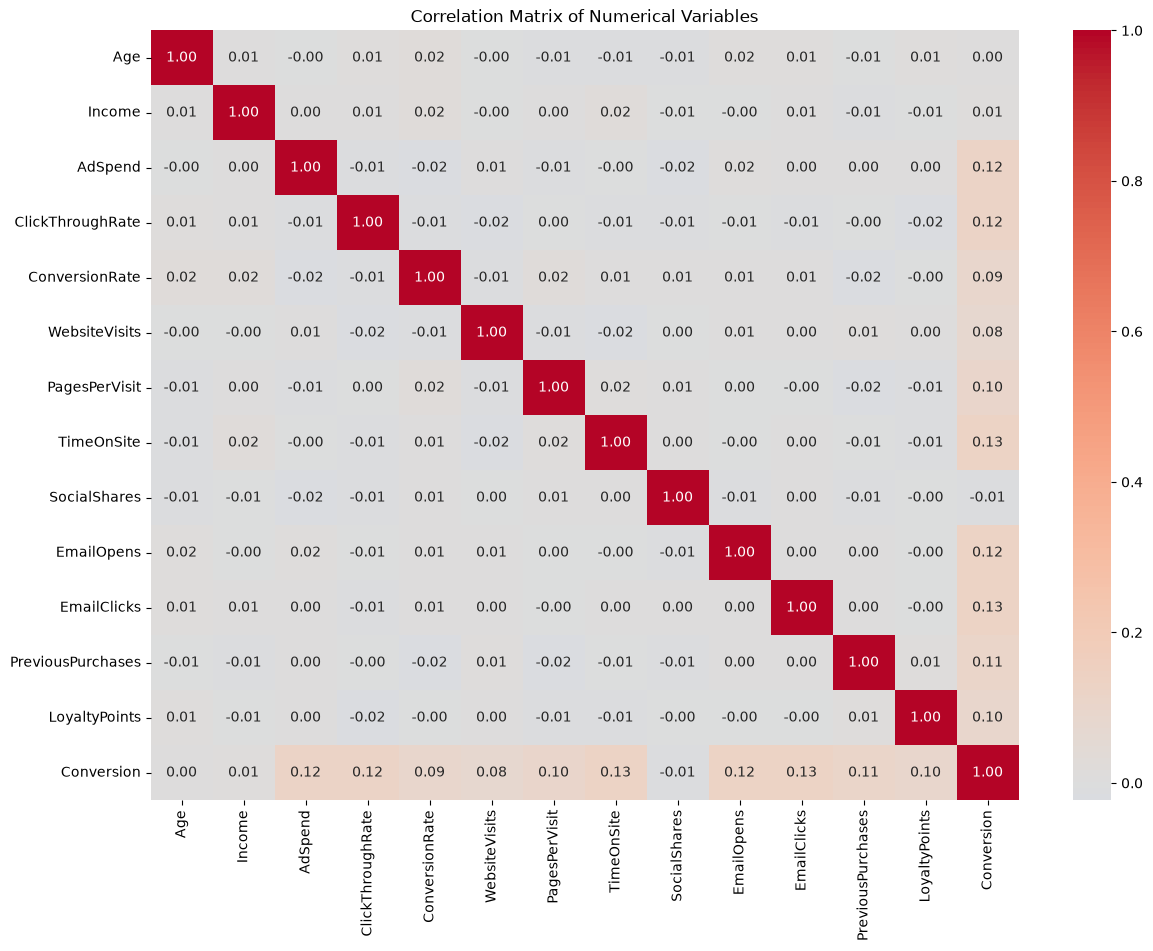

In [351]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f")
plt.title("Correlation Matrix of Numerical Variables")
plt.show()

In [352]:
df["AdSpend"].cov(df["Conversion"])

np.float64(116.41902839573605)

In [353]:
df.groupby("CampaignType")["PagesPerVisit"].mean()

CampaignType
Awareness        5.624965
Consideration    5.589047
Conversion       5.504765
Retention        5.478963
Name: PagesPerVisit, dtype: float64

In [354]:
stats.f_oneway(
    df[df["CampaignType"] == "Awareness"]["PagesPerVisit"],
    df[df["CampaignType"] == "Consideration"]["PagesPerVisit"],
    df[df["CampaignType"] == "Conversion"]["PagesPerVisit"],
    df[df["CampaignType"] == "Retention"]["PagesPerVisit"]
)

F_onewayResult(statistic=np.float64(1.3865239993583403), pvalue=np.float64(0.24482433081991997))

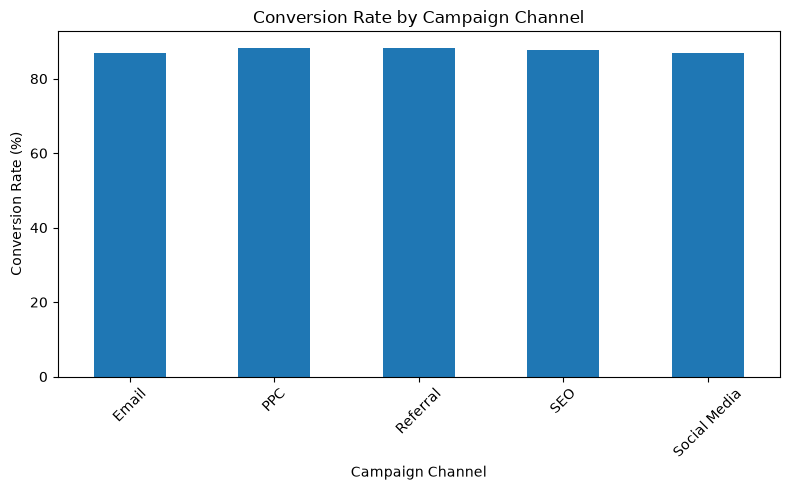

In [355]:
Campaign_Channel_Conversion_Rate.plot(
    kind="bar",
    figsize=(8, 5),
    ylabel="Conversion Rate (%)",
    xlabel="Campaign Channel",
    title="Conversion Rate by Campaign Channel"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

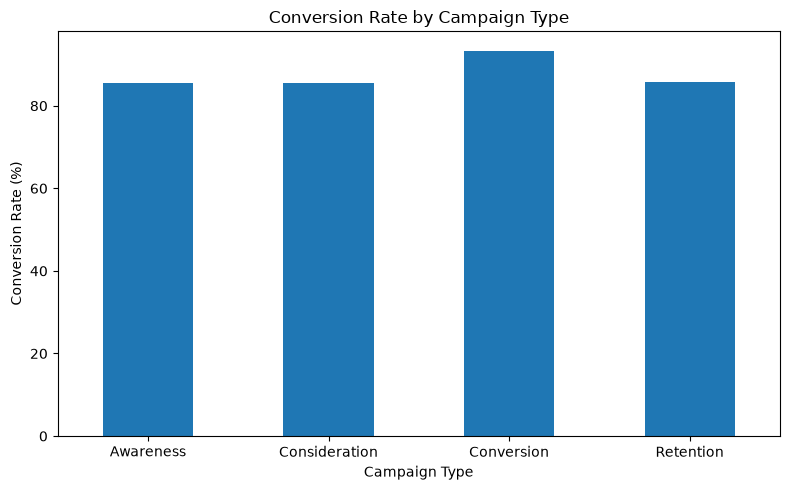

In [356]:
Campaign_Type_Conversion_Rate.plot(
    kind="bar",
    figsize=(8, 5),
    ylabel="Conversion Rate (%)",
    xlabel="Campaign Type",
    title="Conversion Rate by Campaign Type"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

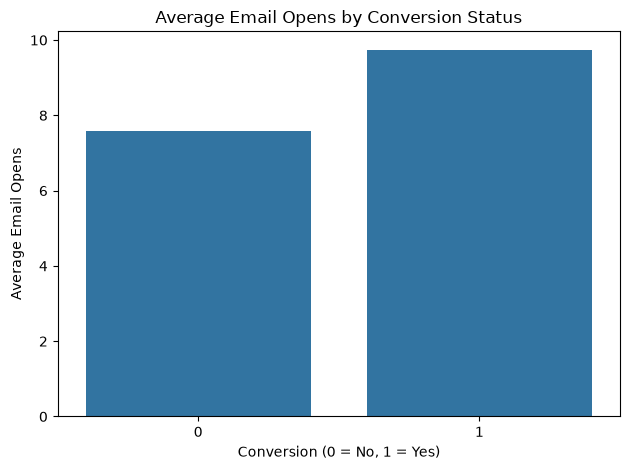

In [357]:
sns.barplot(
    data=df,
    x="Conversion",
    y="EmailOpens",
    estimator="mean",
    errorbar=None
)

plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Average Email Opens")
plt.title("Average Email Opens by Conversion Status")
plt.tight_layout()
plt.show()

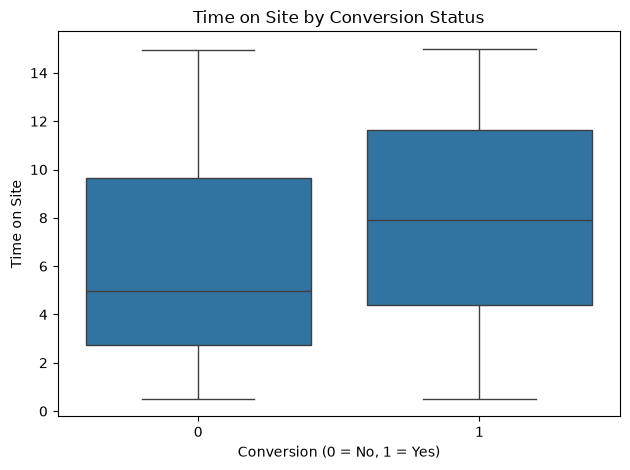

In [358]:
sns.boxplot(
    data=df,
    x="Conversion",
    y="TimeOnSite"
)

plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Time on Site")
plt.title("Time on Site by Conversion Status")
plt.tight_layout()
plt.show()

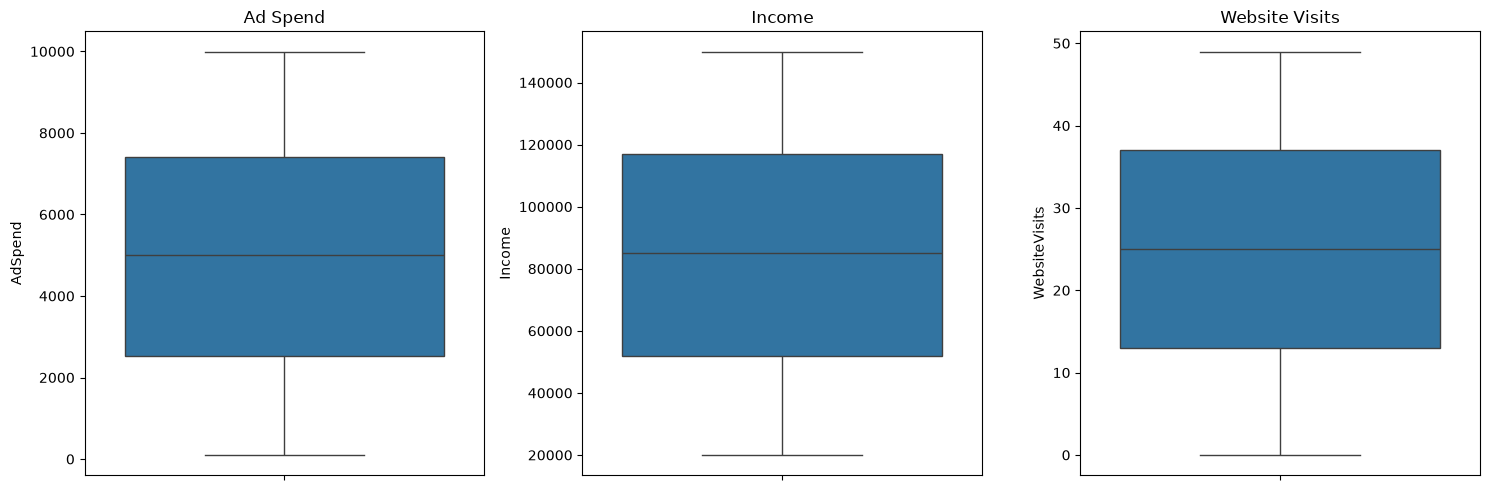

In [359]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=df["AdSpend"], ax=axes[0])
axes[0].set_title("Ad Spend")

sns.boxplot(y=df["Income"], ax=axes[1])
axes[1].set_title("Income")

sns.boxplot(y=df["WebsiteVisits"], ax=axes[2])
axes[2].set_title("Website Visits")

plt.tight_layout()
plt.show()

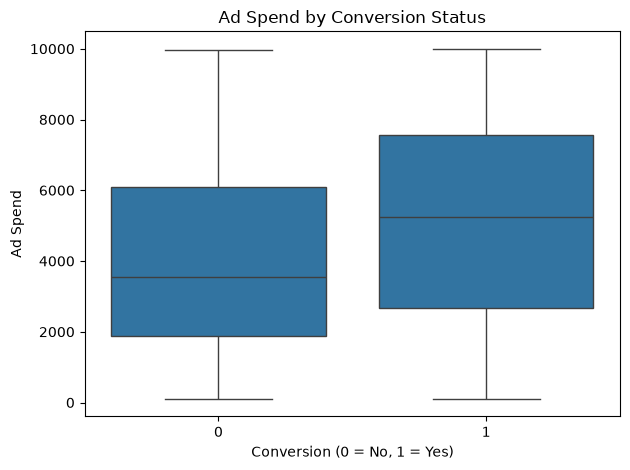

In [360]:
sns.boxplot(
    data=df,
    x="Conversion",
    y="AdSpend"
)

plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Ad Spend")
plt.title("Ad Spend by Conversion Status")
plt.tight_layout()
plt.show()

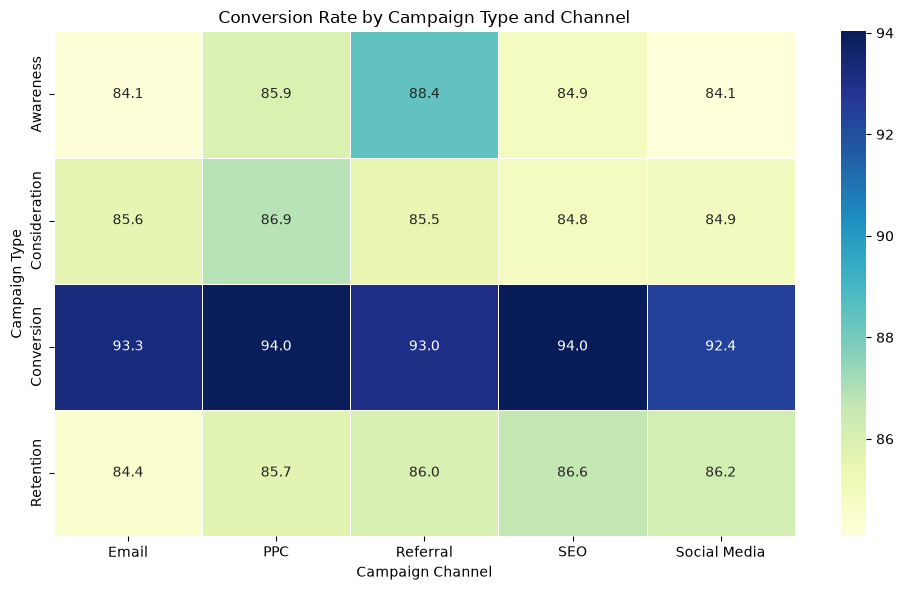

In [361]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    Campaign_Type_Channel_Rate,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Conversion Rate by Campaign Type and Channel")
plt.xlabel("Campaign Channel")
plt.ylabel("Campaign Type")
plt.tight_layout()
plt.show()

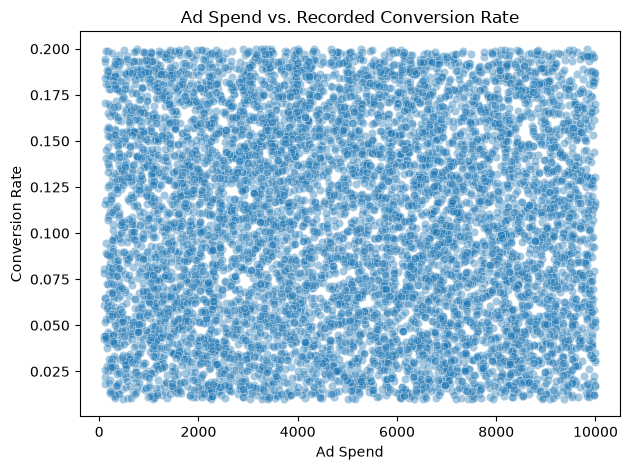

In [362]:
sns.scatterplot(
    data=df,
    x="AdSpend",
    y="ConversionRate",
    alpha=0.4
)

plt.title("Ad Spend vs. Recorded Conversion Rate")
plt.xlabel("Ad Spend")
plt.ylabel("Conversion Rate")
plt.tight_layout()
plt.show()

## 5. Business Insights and Recommendation

Insight 1: Campaign channel performance
- Finding: PPC has the lowest cost per conversion (about 5,612), while Referral has the highest conversion rate (88.31%).
- Recommendation: Investigate PPC as a cost-efficient channel while monitoring Referral's conversion performance.

Insight 2: Campaign type performance
- Finding: The Conversion campaign type has the highest observed conversion rate across all five channels, ranging from 92.37% to 94.03%.
- Recommendation: Investigate what makes these campaigns perform better before deciding whether to allocate more budget to them.

Insight 3: Customer engagement
- Finding: Converted customers have higher average email opens (9.74 vs. 7.58) and spend more time on site (7.93 vs. 6.27, in the dataset's recorded units).
- Recommendation: Investigate whether more effective email engagement and website experiences can support conversion.

Insight 4: Advertising spend
- Finding: AdSpend has a weak positive correlation with the binary Conversion outcome (approximately 0.125). Its correlation with the separate ConversionRate column is approximately −0.020.
- Recommendation: Don't assume that increasing spend will improve conversion. Investigate campaign-level efficiency and other factors.